# Fan out one task per list item

A single node launches one remote task per element of a list and gathers all results with one ray.get.

**When to use it.** Embarrassingly parallel loops: scoring many inputs, calling an API per record, simulating many seeds.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it, edited by hand so that each function is wrapped with `ray.remote` once (the cell's first line says so). The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

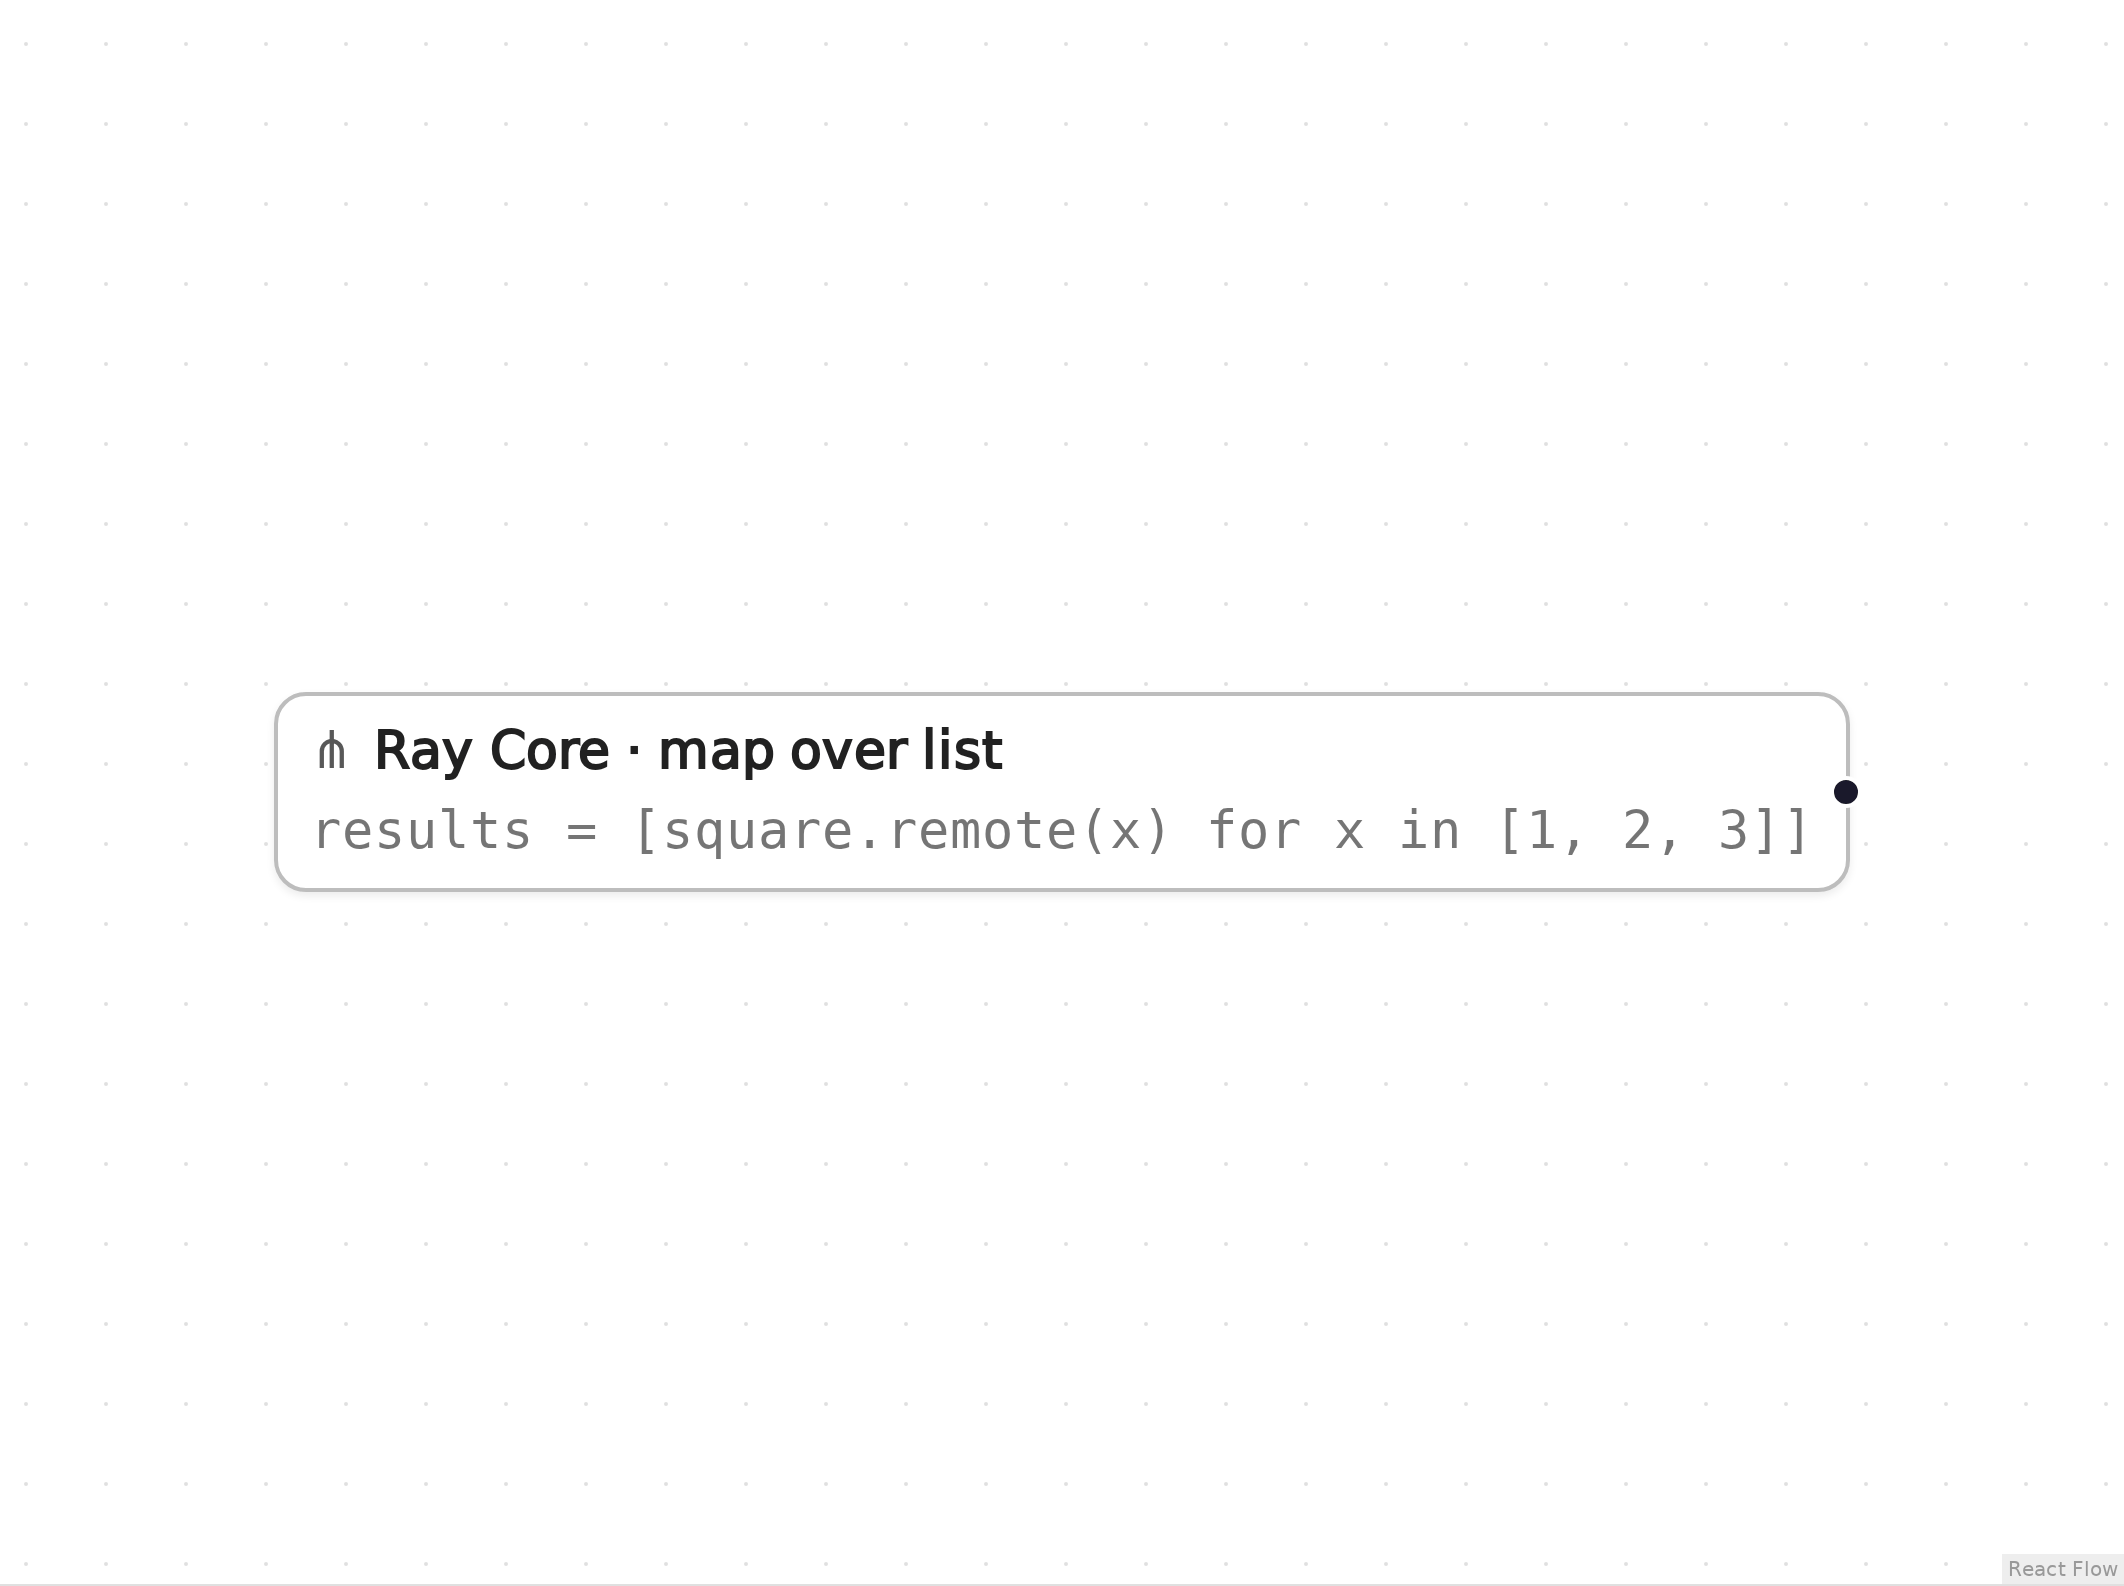

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
def square(x):
    return x * x

## Generated code

This is the cell the visual builder generated from the graph above, with one edit by hand. The builder wrote `ray.remote(square)` inside the list comprehension, so it made a new remote function for every list item, and Ray exports each one to the cluster again; Ray's documentation lists this as an anti-pattern ([Redefining the same remote function or class harms performance](https://docs.ray.io/en/latest/ray-core/patterns/redefine-task-actor-loop.html)). The cell below wraps `square` once and reuses it for every item.

In [3]:
# Generated with Eugo's visual Ray builder, then edited by hand: each function is wrapped with ray.remote once

import ray

if not ray.is_initialized():
    ray.init()

square_task = ray.remote(square)

results = ray.get([square_task.remote(x) for x in [1, 2, 3]])

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert results == [1, 4, 9], results
print("results =", results)

results = [1, 4, 9]


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder, then edited by hand: each function is wrapped with ray.remote once
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated and names the edit made by hand. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Remote function** (line 8, edited by hand)

```python
square_task = ray.remote(square)
```

ray.remote turns the plain function into a remote function, once, before the loop.

**Map over list** (node `n1`, line 10)

```python
results = ray.get([square_task.remote(x) for x in [1, 2, 3]])
```

A list comprehension launches square once per item and a single ray.get collects the results in input order.

## Other ways the builder can emit this graph

The builder can emit the same graph in other forms. They are shown here as text and are not run by this notebook.

### The same graph as a lazy DAG with `bind()`

The builder can emit `.bind()` calls instead of `.remote()`. Nothing runs until `execute()` is called on the last node. This version was also run on Ray 2.55.1 with the same check.

```python
# Generated with Eugo's visual Ray builder, then edited by hand: each function is wrapped with ray.remote once

import ray

if not ray.is_initialized():
    ray.init()

def _fanout(*_args):
    return list(_args)

square_task = ray.remote(square)
fanout_task = ray.remote(_fanout)

_n1 = fanout_task.bind(*[square_task.bind(x) for x in [1, 2, 3]])
results = ray.get(_n1.execute())
```

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()